In [1]:
# ==============================================================
# FINTRUST WEEK 4 — PYTHON ANALYSIS
# IMPORT REQUIRED LIBRARIES
# ==============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load cleaned transaction data

transactions_df = pd.read_csv(
    "Fintrust_Transaction_Data_Cleaned.csv"
)

transactions_df.head()

,Transaction_ID,Customer_ID,Transaction_DateTime,Transaction_Type,Amount_NGN,Channel,Device_Type,Location,International_Transaction,Transaction_Status,Risk_Review_Flag
0,FT-T000001,FT-C01135,1/1/2026 0:00,Card Purchase,5923.80,Mobile App,Android,Enugu,No,Reversed,Yes
1,FT-T000002,FT-C00428,1/1/2026 0:10,Cash Withdrawal,11681.12,ATM,Android,Kaduna,No,Successful,Yes
2,FT-T000003,FT-C00469,1/1/2026 0:21,Transfer,571.91,ATM,POS Terminal,Kano,No,Successful,No
3,FT-T000004,FT-C01015,1/1/2026 0:32,Deposit,105367.52,Mobile App,Web Browser,Abuja,No,Successful,No
4,FT-T000005,FT-C00870,1/1/2026 0:43,Cash Withdrawal,3049.06,Mobile App,POS Terminal,Abuja,No,Successful,No


,Transaction_DateTime,Total_Transactions,Total_Transaction_Value
0,2026-01-01,4133,1.884894e+08
1,2026-02-01,3734,1.757869e+08
2,2026-03-01,4133,1.962010e+08


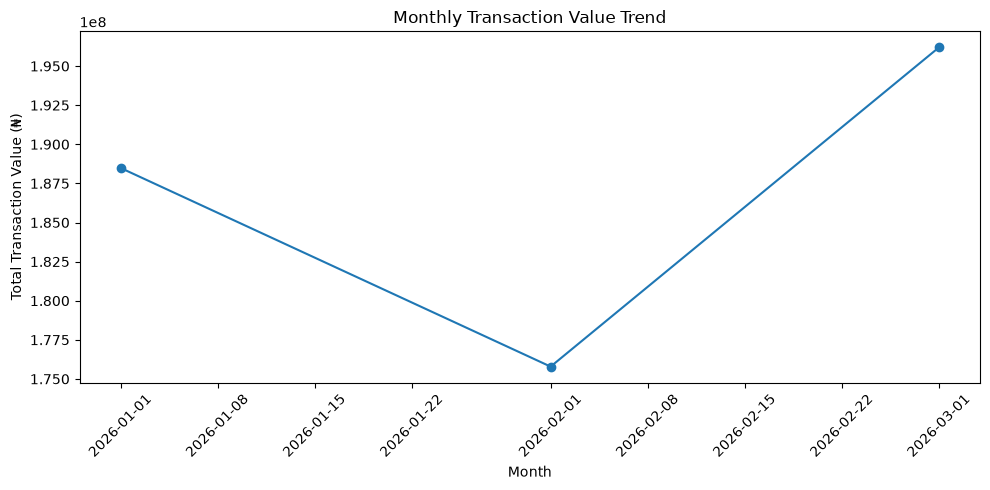

In [ ]:
# ==============================================================
# FINTRUST WEEK 4 — PYTHON ANALYSIS 1
# TITLE: Monthly Transaction Trend
# ==============================================================

# Convert transaction date to datetime
transactions_df['Transaction_DateTime'] = pd.to_datetime(
    transactions_df['Transaction_DateTime']
)

# Create monthly transaction summary
monthly_trend = (
    transactions_df
    .groupby(
        transactions_df['Transaction_DateTime'].dt.to_period('M')
    )
    .agg(
        Total_Transactions=('Transaction_ID', 'count'),
        Total_Transaction_Value=('Amount_NGN', 'sum')
    )
    .reset_index()
)

# Convert month back to datetime
monthly_trend['Transaction_DateTime'] = (
    monthly_trend['Transaction_DateTime'].dt.to_timestamp()
)

# Display monthly results
display(monthly_trend)

# Plot monthly transaction value
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_trend['Transaction_DateTime'],
    monthly_trend['Total_Transaction_Value'],
    marker='o'
)

plt.title('Monthly Transaction Value Trend')
plt.xlabel('Month')
plt.ylabel('Total Transaction Value (₦)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Customer_Segment,Total_Transactions,Total_Transaction_Value,Average_Transaction_Amount
0,Everyday,5644,2.614589e+08,46325.11
1,Premium,2361,1.077512e+08,45637.95
3,Student,2289,1.074759e+08,46953.20
2,SME,1706,8.379137e+07,49115.69


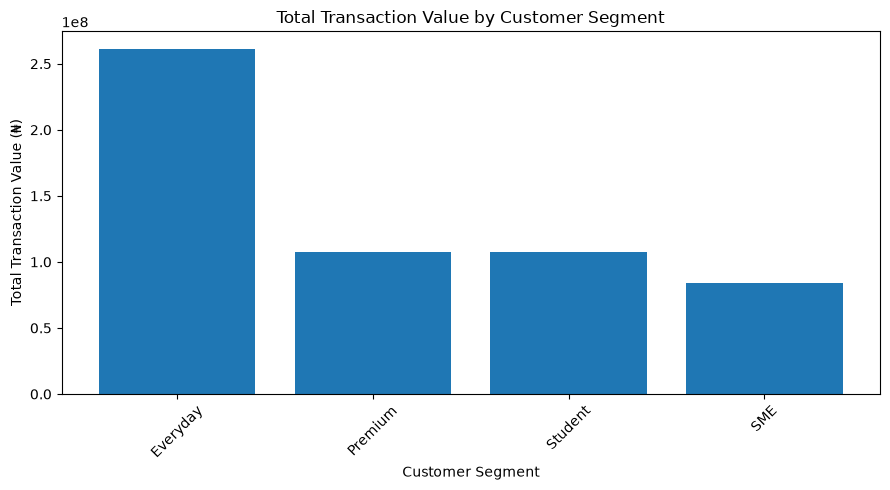

In [ ]:
# ==============================================================
# FINTRUST WEEK 4 — PYTHON ANALYSIS 2
# TITLE: Customer Segment Performance Comparison
# ==============================================================

# Load customer data
customers_df = pd.read_csv("Fintrust_Customer.csv")

# Merge customer segment information with transactions
segment_df = transactions_df.merge(
    customers_df[['Customer_ID', 'Customer_Segment']],
    on='Customer_ID',
    how='left'
)

# Calculate segment performance
segment_performance = (
    segment_df
    .groupby('Customer_Segment')
    .agg(
        Total_Transactions=('Transaction_ID', 'count'),
        Total_Transaction_Value=('Amount_NGN', 'sum'),
        Average_Transaction_Amount=('Amount_NGN', 'mean')
    )
    .reset_index()
)

# Round numerical values
segment_performance[
    ['Total_Transaction_Value', 'Average_Transaction_Amount']
] = segment_performance[
    ['Total_Transaction_Value', 'Average_Transaction_Amount']
].round(2)

# Sort by total transaction value
segment_performance = segment_performance.sort_values(
    'Total_Transaction_Value',
    ascending=False
)

# Display results
display(segment_performance)

# Plot total transaction value by segment
plt.figure(figsize=(9, 5))

plt.bar(
    segment_performance['Customer_Segment'],
    segment_performance['Total_Transaction_Value']
)

plt.title('Total Transaction Value by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Transaction Value (₦)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Channel,Total_Transactions,Successful_Transactions,Total_Transaction_Value,Success_Rate
0,ATM,1747,1602,8.394235e+07,91.70
2,POS,2393,2174,1.043467e+08,90.85
4,Web,1869,1698,8.932500e+07,90.85
3,USSD,889,803,4.275895e+07,90.33
1,Mobile App,5102,4579,2.401044e+08,89.75


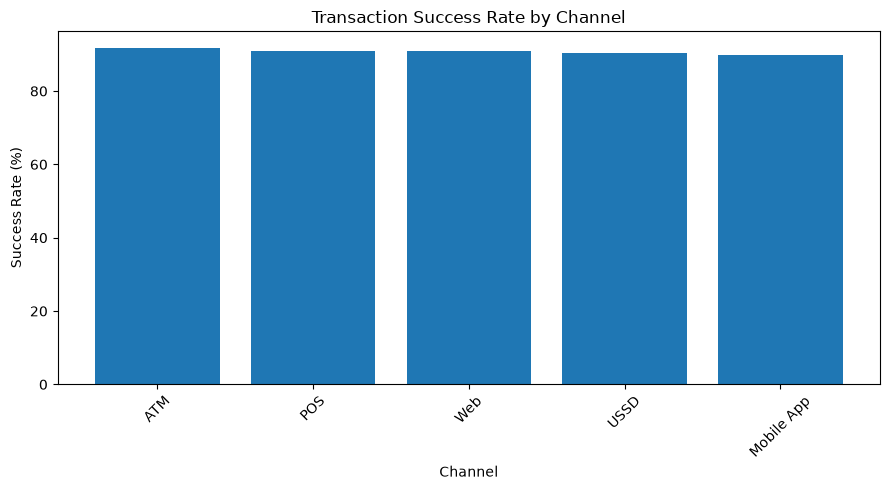

In [ ]:
# ==============================================================
# FINTRUST WEEK 4 — PYTHON ANALYSIS 3
# TITLE: Channel Performance Comparison
# ==============================================================

# Calculate channel performance
channel_performance = (
    transactions_df
    .groupby('Channel')
    .agg(
        Total_Transactions=('Transaction_ID', 'count'),
        Successful_Transactions=(
            'Transaction_Status',
            lambda x: (x == 'Successful').sum()
        ),
        Total_Transaction_Value=('Amount_NGN', 'sum')
    )
    .reset_index()
)

# Calculate success rate
channel_performance['Success_Rate'] = (
    channel_performance['Successful_Transactions']
    / channel_performance['Total_Transactions']
    * 100
).round(2)

# Round transaction value
channel_performance['Total_Transaction_Value'] = (
    channel_performance['Total_Transaction_Value']
    .round(2)
)

# Sort by success rate
channel_performance = channel_performance.sort_values(
    'Success_Rate',
    ascending=False
)

# Display results
display(channel_performance)

# Plot success rate by channel
plt.figure(figsize=(9, 5))

plt.bar(
    channel_performance['Channel'],
    channel_performance['Success_Rate']
)

plt.title('Transaction Success Rate by Channel')
plt.xlabel('Channel')
plt.ylabel('Success Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Activity_Level,Total_Customers,Total_Transactions,Total_Transaction_Value,Average_Transaction_Value
0,High Activity,29,474,2.235606e+07,47163.40
1,Low Activity,693,3842,1.765608e+08,45457.03
2,Medium Activity,778,7684,3.615605e+08,46976.68


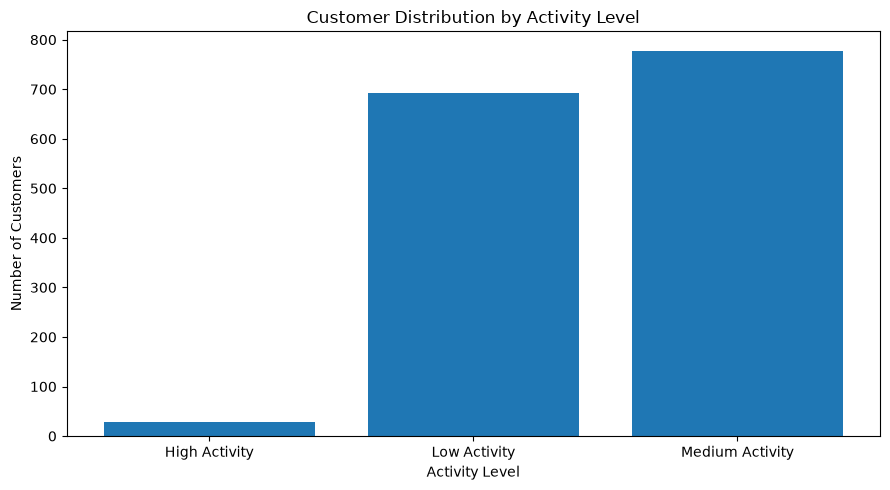

In [ ]:
# ==============================================================
# FINTRUST WEEK 4 — PYTHON ANALYSIS 4
# TITLE: Customer Activity Segmentation
# ==============================================================

# Calculate customer transaction activity
customer_activity = (
    segment_df
    .groupby(['Customer_ID', 'Customer_Segment'])
    .agg(
        Total_Transactions=('Transaction_ID', 'count'),
        Total_Transaction_Value=('Amount_NGN', 'sum'),
        Average_Transaction_Amount=('Amount_NGN', 'mean')
    )
    .reset_index()
)

# Create activity segments using business-defined transaction thresholds
customer_activity['Activity_Level'] = np.select(
    [
        customer_activity['Total_Transactions'] >= 15,
        customer_activity['Total_Transactions'] >= 8
    ],
    [
        'High Activity',
        'Medium Activity'
    ],
    default='Low Activity'
)

# Summarize activity levels
activity_summary = (
    customer_activity
    .groupby('Activity_Level', observed=True)
    .agg(
        Total_Customers=('Customer_ID', 'count'),
        Total_Transactions=('Total_Transactions', 'sum'),
        Total_Transaction_Value=('Total_Transaction_Value', 'sum'),
        Average_Transaction_Value=(
            'Average_Transaction_Amount', 'mean'
        )
    )
    .reset_index()
)

# Round numerical values
activity_summary[
    ['Total_Transaction_Value', 'Average_Transaction_Value']
] = activity_summary[
    ['Total_Transaction_Value', 'Average_Transaction_Value']
].round(2)

# Display results
display(activity_summary)

# Plot customer distribution by activity level
plt.figure(figsize=(9, 5))

plt.bar(
    activity_summary['Activity_Level'].astype(str),
    activity_summary['Total_Customers']
)

plt.title('Customer Distribution by Activity Level')
plt.xlabel('Activity Level')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================
# FINTRUST WEEK 4 — PYTHON ANALYSIS 5
# TITLE: Validation of Week 2 Customer Segment Finding(Validation 1)
# ==============================================================

# Calculate transaction value by customer segment
validation = (
    segment_df
    .groupby('Customer_Segment')
    .agg(
        Total_Transaction_Value=('Amount_NGN', 'sum'),
        Total_Transactions=('Transaction_ID', 'count')
    )
    .reset_index()
)

# Round transaction values
validation['Total_Transaction_Value'] = (
    validation['Total_Transaction_Value'].round(2)
)

# Identify the segment with the highest transaction value
highest_value_segment = validation.loc[
    validation['Total_Transaction_Value'].idxmax()
]

# Display validation results
display(validation.sort_values(
    'Total_Transaction_Value',
    ascending=False
))

print(
    f"Highest transaction-value segment: "
    f"{highest_value_segment['Customer_Segment']}"
)

print(
    f"Transaction value: ₦"
    f"{highest_value_segment['Total_Transaction_Value']:,.2f}"
)

# Validation check
expected_segment = "Everyday"

if highest_value_segment['Customer_Segment'] == expected_segment:
    print("VALIDATION RESULT: Week 2 finding is confirmed.")
else:
    print("VALIDATION RESULT: Week 2 finding is not confirmed.")

,Customer_Segment,Total_Transaction_Value,Total_Transactions
0,Everyday,2.614589e+08,5644
1,Premium,1.077512e+08,2361
3,Student,1.074759e+08,2289
2,SME,8.379137e+07,1706


Highest transaction-value segment: Everyday
Transaction value: ₦261,458,920.99
VALIDATION RESULT: Week 2 finding is confirmed.


In [8]:
# ==============================================================
# FINTRUST WEEK 4 — VALIDATION 2
# TITLE: Validation of Channel Performance Finding
# ==============================================================

channel_validation = (
    transactions_df
    .groupby('Channel')
    .agg(
        Total_Transactions=('Transaction_ID', 'count'),
        Successful_Transactions=(
            'Transaction_Status',
            lambda x: (x == 'Successful').sum()
        ),
        Total_Transaction_Value=('Amount_NGN', 'sum')
    )
    .reset_index()
)

channel_validation['Success_Rate'] = (
    channel_validation['Successful_Transactions']
    / channel_validation['Total_Transactions']
    * 100
).round(2)

channel_validation['Total_Transaction_Value'] = (
    channel_validation['Total_Transaction_Value'].round(2)
)

display(
    channel_validation.sort_values(
        'Success_Rate',
        ascending=False
    )
)

,Channel,Total_Transactions,Successful_Transactions,Total_Transaction_Value,Success_Rate
0,ATM,1747,1602,8.394235e+07,91.70
2,POS,2393,2174,1.043467e+08,90.85
4,Web,1869,1698,8.932500e+07,90.85
3,USSD,889,803,4.275895e+07,90.33
1,Mobile App,5102,4579,2.401044e+08,89.75


In [9]:
# ==============================================================
# FINTRUST WEEK 4 — VALIDATION 3
# TITLE: Validation of Risk Review by Customer Segment
# ==============================================================

risk_segment_validation = (
    segment_df
    .groupby('Customer_Segment')
    .agg(
        Total_Transactions=('Transaction_ID', 'count'),
        Risk_Reviewed_Transactions=(
            'Risk_Review_Flag',
            lambda x: (x == 'Yes').sum()
        ),
        Total_Transaction_Value=('Amount_NGN', 'sum')
    )
    .reset_index()
)

risk_segment_validation['Risk_Review_Rate'] = (
    risk_segment_validation['Risk_Reviewed_Transactions']
    / risk_segment_validation['Total_Transactions']
    * 100
).round(2)

risk_segment_validation['Total_Transaction_Value'] = (
    risk_segment_validation['Total_Transaction_Value'].round(2)
)

display(
    risk_segment_validation.sort_values(
        'Risk_Review_Rate',
        ascending=False
    )
)

,Customer_Segment,Total_Transactions,Risk_Reviewed_Transactions,Total_Transaction_Value,Risk_Review_Rate
1,Premium,2361,480,1.077512e+08,20.33
3,Student,2289,452,1.074759e+08,19.75
2,SME,1706,331,8.379137e+07,19.40
0,Everyday,5644,1089,2.614589e+08,19.29


In [10]:
# ==============================================================
# FINTRUST WEEK 4 — VALIDATION 4
# TITLE: Validation of International vs Domestic Risk Pattern
# ==============================================================

international_risk_validation = (
    transactions_df
    .groupby('International_Transaction')
    .agg(
        Total_Transactions=('Transaction_ID', 'count'),
        Risk_Reviewed_Transactions=(
            'Risk_Review_Flag',
            lambda x: (x == 'Yes').sum()
        ),
        Total_Transaction_Value=('Amount_NGN', 'sum')
    )
    .reset_index()
)

international_risk_validation['Risk_Review_Rate'] = (
    international_risk_validation['Risk_Reviewed_Transactions']
    / international_risk_validation['Total_Transactions']
    * 100
).round(2)

international_risk_validation['Total_Transaction_Value'] = (
    international_risk_validation['Total_Transaction_Value'].round(2)
)

display(international_risk_validation)

,International_Transaction,Total_Transactions,Risk_Reviewed_Transactions,Total_Transaction_Value,Risk_Review_Rate
0,No,11520,2175,5.404816e+08,18.88
1,Yes,480,177,1.999578e+07,36.88


In [11]:
# ==============================================================
# FINTRUST WEEK 4 — VALIDATION 5
# TITLE: Validation of Monthly Transaction Trend
# ==============================================================

monthly_validation = transactions_df.copy()

monthly_validation['Transaction_DateTime'] = pd.to_datetime(
    monthly_validation['Transaction_DateTime']
)

monthly_validation['Month'] = (
    monthly_validation['Transaction_DateTime']
    .dt.to_period('M')
    .dt.to_timestamp()
)

monthly_validation = (
    monthly_validation
    .groupby('Month')
    .agg(
        Total_Transactions=('Transaction_ID', 'count'),
        Total_Transaction_Value=('Amount_NGN', 'sum')
    )
    .reset_index()
)

monthly_validation['Total_Transaction_Value'] = (
    monthly_validation['Total_Transaction_Value'].round(2)
)

display(monthly_validation)

,Month,Total_Transactions,Total_Transaction_Value
0,2026-01-01,4133,1.884894e+08
1,2026-02-01,3734,1.757869e+08
2,2026-03-01,4133,1.962010e+08


### Validation 5 Conclusion

The monthly transaction analysis confirms the previously identified transaction trend. Transaction volume decreased from 4,133 in January to 3,734 in February, before recovering to 4,133 in March. This confirms that February represented a temporary decline in transaction activity, followed by a recovery in March.

## Week 4 Validation Summary

Five important findings were validated using independent Python calculations:

1. Customer Segment Performance
2. Channel Performance
3. Risk Review by Customer Segment
4. International vs Domestic Risk
5. Monthly Transaction Trend

The validation results will be compared with the corresponding SQL and
Power BI outputs. Any discrepancy will be investigated and documented
before the final business insights are confirmed.